# Detecção de amastigotas fora do macrófago — experimento 4 (YOLO26-large)

- Autor: Clésio Gonçalves
- Quarto experimento da série. Mesmo problema (classe única `leishmania` fora do macrófago, mesmos recortes 512x512, mesmos 6 folds), agora com **YOLO26-large** (`yolo26l.pt`, ~26.3M parâmetros), o maior modelo testado até aqui.
- GPU validada com teste rápido antes do treino completo: `batch=16` em `imgsz=640` usa ~11 GB de VRAM (GPU de 16 GB livre).
- Ver `deteccao_yolov11nano.ipynb` (Exp.1), `deteccao_yolov11_p2_melhorias.ipynb` (Exp.2) e `deteccao_yolov26m.ipynb` (Exp.3) para os experimentos anteriores da série.

## Resultado e conclusão da série de 4 experimentos

| Experimento | Modelo | Parâmetros | mAP50 médio | Desvio padrão |
|---|---|---|---|---|
| 1 | YOLO11n | 2.6M | 0.4391 | 0.1229 |
| 2 | YOLO11n + cabeça P2 | 2.7M | 0.4226 | 0.1083 |
| 3 | YOLO26-medium | 21.9M | 0.4272 | 0.1068 |
| 4 | YOLO26-large | 26.3M | **0.3943** | 0.1000 |

**Aumentar a capacidade do modelo não melhorou os resultados — pelo contrário, o YOLO26-large teve o pior mAP50 da série**, embora a diferença esteja dentro da margem de desvio padrão entre folds (ou seja, não é uma queda estatisticamente conclusiva, mas claramente não há ganho). Os 4 experimentos convergem para o mesmo patamar (mAP50 ≈ 0.39–0.44), o que indica que o fator limitante **não é a arquitetura ou o tamanho do modelo**, e sim a capacidade de generalizar entre lâminas diferentes (cada fold testa em lâminas nunca vistas no treino, provavelmente com variação de coloração/preparo entre lâminas). A comparação visual especialista-vs-YOLO (lâmina `leish_3`, pior caso deste experimento) mostra o mesmo padrão de falha observado nos experimentos anteriores: poucos acertos e vários falsos positivos.

**Próximos passos sugeridos** (fora do escopo desta rodada): normalização de cor/coloração entre lâminas antes do treino, aumentar a quantidade de lâminas anotadas, ou re-examinar a qualidade/consistência das anotações nas lâminas com pior desempenho (`leish_3`, `leish_4`).

## Utilização da GPU

In [1]:
!nvidia-smi

Tue Jun 23 16:19:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   33C    P8             16W /  300W |      15MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

PIL        : 12.0.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) de macrófagos infectados, organizados por lâmina — gerados em pre_processamento_dataset_recortes.ipynb
diretorio_recortes = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")
extensao = '.png'

# Tamanho de treino/inferência da rede
tamanho_imagem = 640

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho (dataset YOLO compartilhado com os experimentos anteriores; runs em pasta própria)
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold_yolo26l")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO26-large
caminho_pesos_pretreinados = 'yolo26l.pt'

# Hiperparâmetros de treinamento (mesmo esquema dos experimentos 2 e 3, validado com teste rápido de memória)
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=16,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    scale=0.3,
    single_cls=True,
    verbose=False,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')

,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")

Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")

6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds (YOLO26-large)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo26l.pt`. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [11]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=40, perspective=0.0, plots=True, pose=12.0, pretrained=Tr

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 


... (28,434 outputs left out)

                   all         96        831      0.522      0.354      0.389      0.178


Speed: 0.1ms preprocess, 3.4ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo26l/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo26l/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [12]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO26l summary (fused): 190 layers, 24,746,511 parameters, 0 gradients, 86.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3572.7±233.4 MB/s, size: 258.3 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 6.2Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 1.7it/s 0.2s<13.9s

... (122 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 9.8it/s 3.1s

                   all        480       1634      0.375      0.397      0.319      0.136


Speed: 0.2ms preprocess, 5.5ms inference, 0.0ms loss, 0.0ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.466031,0.450475,0.385208,0.116888
2,"leish_2, leish_7",0.553847,0.566496,0.532822,0.209565
3,"leish_1, leish_8",0.333118,0.375754,0.261246,0.106320
4,"leish_4, leish_9",0.385189,0.500415,0.387015,0.160322
5,"leish_1, leish_7",0.552026,0.488760,0.480104,0.193689
6,"leish_2, leish_8",0.374976,0.397185,0.319460,0.135981


In [13]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)

,média,desvio_padrão
precisao,0.4442,0.0946
recall,0.4632,0.0705
mAP50,0.3943,0.1000
mAP50-95,0.1538,0.0417


## Comparação com os experimentos anteriores

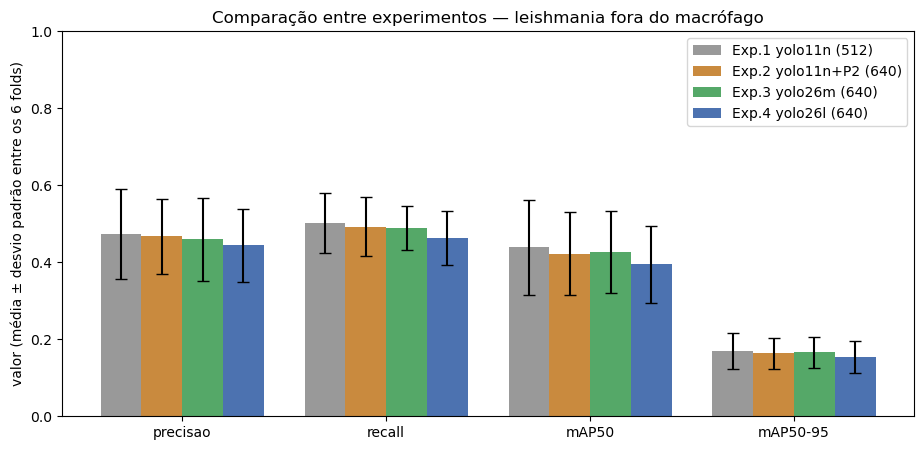

In [14]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores, copiados aqui apenas para referência visual (mesmos 6 folds)
resumo_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.4735, 'recall': 0.5012, 'mAP50': 0.4391, 'mAP50-95': 0.1695}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.4672, 'recall': 0.4922, 'mAP50': 0.4226, 'mAP50-95': 0.1640}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.4595, 'recall': 0.4894, 'mAP50': 0.4272, 'mAP50-95': 0.1659}),
}
desvios_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.1164, 'recall': 0.0780, 'mAP50': 0.1229, 'mAP50-95': 0.0457}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.0981, 'recall': 0.0763, 'mAP50': 0.1083, 'mAP50-95': 0.0405}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.1079, 'recall': 0.0567, 'mAP50': 0.1068, 'mAP50-95': 0.0396}),
}

metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
nomes_exp = list(resumo_experimentos_anteriores.keys()) + ['Exp.4 yolo26l (640)']
medias_exp = [resumo_experimentos_anteriores[n][metricas_plot] for n in resumo_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'média']]
desvios_exp = [desvios_experimentos_anteriores[n][metricas_plot] for n in desvios_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'desvio_padrão']]

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.8 / n_exp
cores = ['#999999', '#c98a3e', '#55a868', '#4C72B0']

fig, ax = plt.subplots(figsize=(11, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=4, label=nome, color=cores[i % len(cores)])

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend()
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [15]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO26l summary (fused): 190 layers, 24,746,511 parameters, 0 gradients, 86.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6039.2±822.5 MB/s, size: 269.7 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 4.5Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.6it/s 0.2s<0.6s

... (172 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 10.3it/s 2.2s

                   all        353        992      0.382      0.426      0.332      0.147


Speed: 0.2ms preprocess, 5.5ms inference, 0.0ms loss, 0.0ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.600181,0.298059,0.409213,0.181075
1,leish_1,5,0.473354,0.255258,0.298241,0.136674
2,leish_2,2,0.251160,0.431464,0.228759,0.088262
3,leish_2,6,0.346097,0.437695,0.323838,0.126962
4,leish_3,1,0.161195,0.300000,0.109929,0.039963
5,leish_4,4,0.236040,0.257576,0.141364,0.067670
6,leish_5,1,0.467988,0.453122,0.387508,0.117550
7,leish_7,2,0.620732,0.643050,0.616751,0.244279
8,leish_7,5,0.593357,0.570754,0.562574,0.224183
9,leish_8,3,0.320450,0.451613,0.290725,0.114885


In [16]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)

precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.5368  0.0897     2  0.2767  0.0303     2  0.3537  0.0785     2   
leish_2   0.2986  0.0671     2  0.4346  0.0044     2  0.2763  0.0672     2   
leish_3   0.1612     NaN     1  0.3000     NaN     1  0.1099     NaN     1   
leish_4   0.2360     NaN     1  0.2576     NaN     1  0.1414     NaN     1   
leish_5   0.4680     NaN     1  0.4531     NaN     1  0.3875     NaN     1   
leish_7   0.6070  0.0194     2  0.6069  0.0511     2  0.5897  0.0383     2   
leish_8   0.3510  0.0433     2  0.4390  0.0178     2  0.3113  0.0292     2   
leish_9   0.4401     NaN     1  0.5387     NaN     1  0.4465     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.1589  0.0314     2  
leish_2   0.1076  0.0274     2  
leish_3   0.0400     NaN     1  
leish_4   0.0677     NaN     1  
leish_5   0.1176     NaN     1  
leish_7   0.2342  0.0142     2  
leish_8   0.1307  0.0224     2  
leish_9   0.1831     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima.

In [17]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img = Image.open(caminho_imagem)
    largura, altura = img.size
    eixo.imshow(img)

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']

Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_3


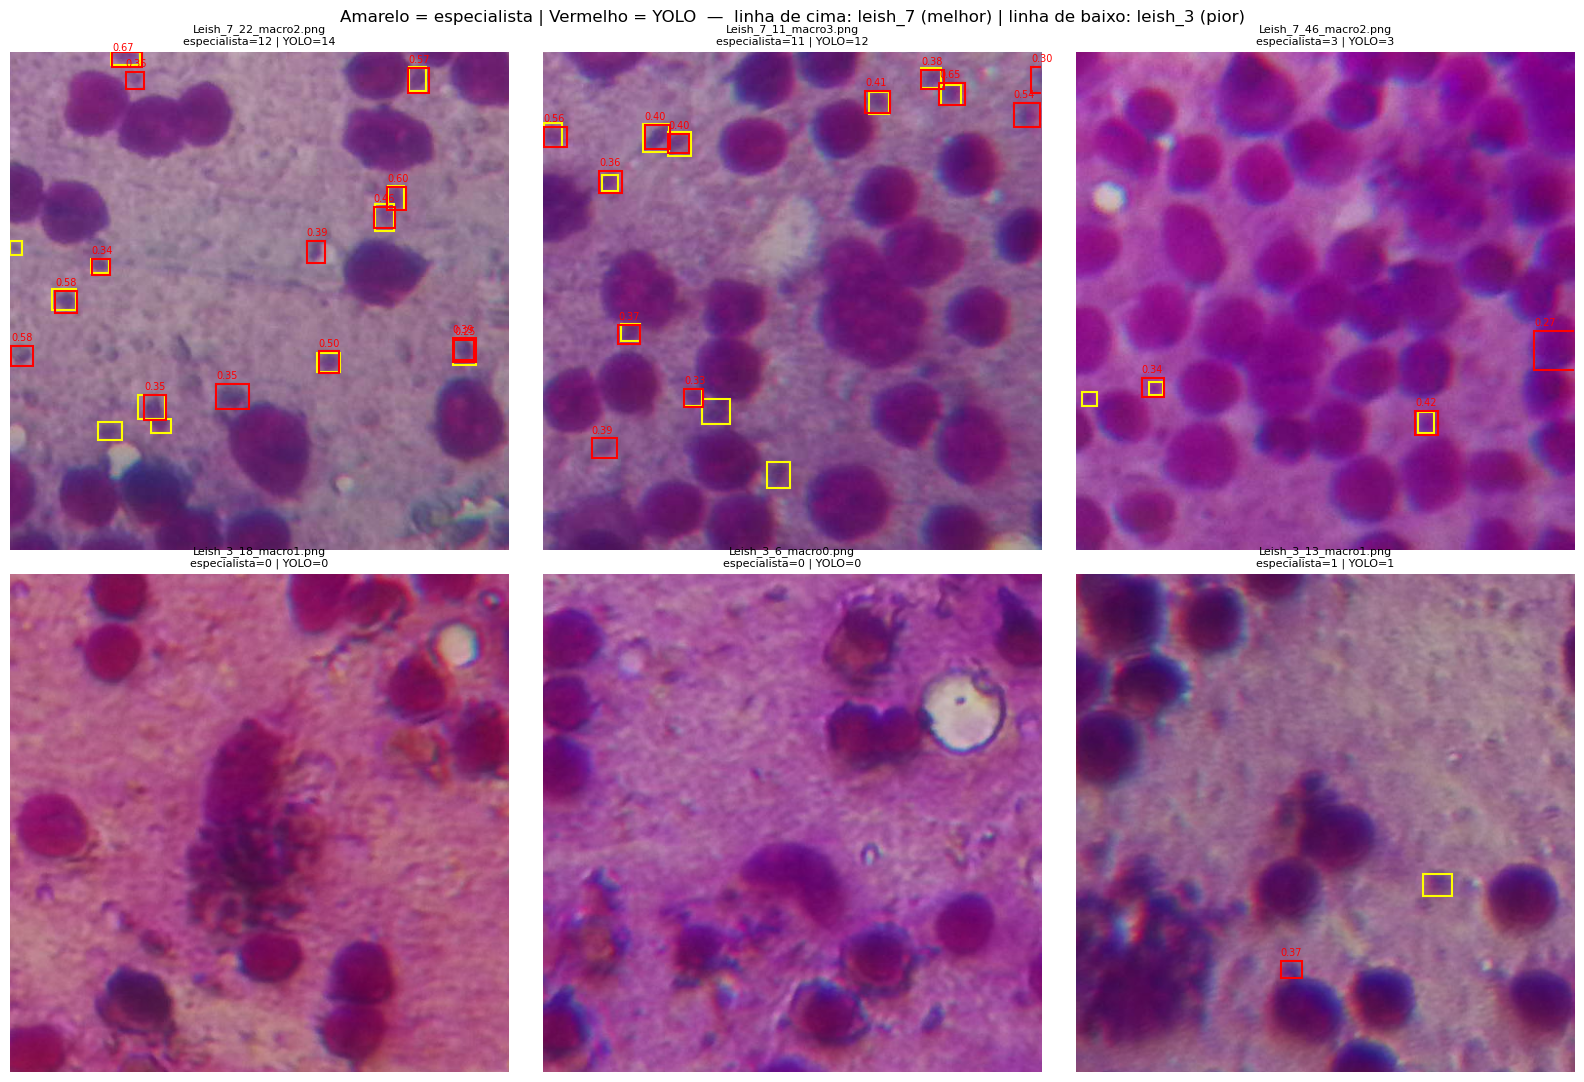

In [18]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()